In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

# Polynomial Regression
$$
y = 0.5x^3 - 3x^2 + 2x + noise
$$

In [12]:
n = 120
X = np.linspace(-4, 6, n).reshape(-1, 1)
noise = np.random.normal(0, 6, n)

In [13]:
y = 0.5*X.flatten()**3 - 3*X.flatten()**2 + 2*X.flatten() + noise

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state =42)
len(X_train), len(X_test)

(90, 30)

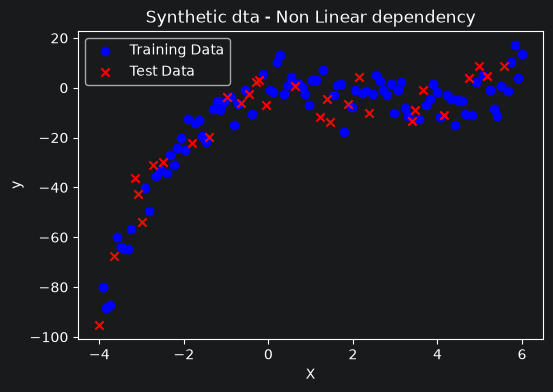

In [15]:
plt.figure(figsize=(6, 4))
plt.scatter(X_train, y_train, color = 'blue', label = 'Training Data')
plt.scatter(X_test, y_test, color = 'red', label = 'Test Data', marker = 'x')
plt.title('Synthetic dta - Non Linear dependency')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()

plt.show()

In [16]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_train_lin = linear_model.predict(X_train)
y_pred_test_lin = linear_model.predict(X_test)

rmse_train_lin = root_mean_squared_error(y_train, y_pred_train_lin)
rmse_test_lin = root_mean_squared_error(y_test, y_pred_test_lin)

r2_train_lin = r2_score(y_train, y_pred_train_lin)
r2_test_lin = r2_score(y_test, y_pred_test_lin)

print(f'''
Linear Regression Model:
    Train RMSE: {rmse_train_lin}
    Test RMSE: {rmse_test_lin}
    Train R2 Score: {r2_train_lin}
    Test R2 Score: {r2_test_lin}
''')


Linear Regression Model:
    Train RMSE: 15.914964482793962
    Test RMSE: 15.962790340911598
    Train R2 Score: 0.47360336683596205
    Test R2 Score: 0.5363076160792493



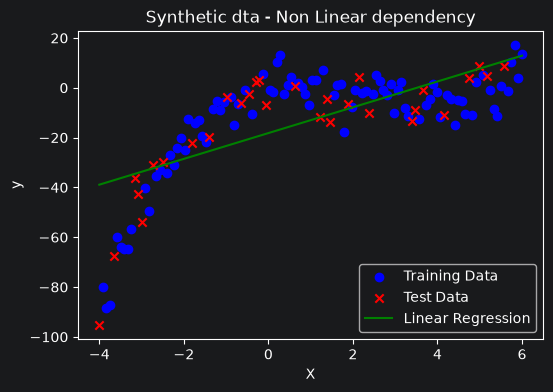

In [17]:
X_grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
y_grid = linear_model.predict(X_grid)

plt.figure(figsize=(6, 4))
plt.scatter(X_train, y_train, color = 'blue', label = 'Training Data')
plt.scatter(X_test, y_test, color = 'red', label = 'Test Data', marker = 'x')
plt.plot(X_grid, y_grid, color = 'green', label = 'Linear Regression')
plt.title('Synthetic dta - Non Linear dependency')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()

plt.show()

In [18]:
from sklearn.model_selection import KFold

poly_pipe = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False)),
    ('linear', LinearRegression())
])

param_grid = {
    'poly__degree': list(range(1, 11)),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(
    estimator=poly_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

grid.fit(X_train, y_train)
best_degree = grid.best_params_['poly__degree']
best_cv_rmse = -grid.best_score_

print(
    f'''Polynomial Regression Model:
        Polynomial Degree: {best_degree}
        Best CV RMSE: {best_cv_rmse:.3f}

''',
)

Polynomial Regression Model:
        Polynomial Degree: 3
        Best CV RMSE: 6.105




In [21]:
rows = []

for d in range(1, 11):
    pipe = Pipeline(
        [
            ('poly', PolynomialFeatures(include_bias=False, degree=d)),
            ('linear', LinearRegression())
        ]
    )
    pipe.fit(X_train, y_train)
    y_tr = pipe.predict(X_train)
    y_te = pipe.predict(X_test)

    rows.append(
        {
            'degree': d,
            'train_rmse': root_mean_squared_error(y_train, y_tr),
            'test_rmse': root_mean_squared_error(y_test, y_te),
            'train_r2': r2_score(y_train, y_tr),
            'test_r2': r2_score(y_test, y_te),
        }
    )
metrics_df = pd.DataFrame(rows).set_index('degree')
metrics_df

,train_rmse,test_rmse,train_r2,test_r2
degree,,,,
1,15.914964,15.962790,0.473603,0.536308
2,10.447122,11.540713,0.773173,0.757631
3,5.594083,7.533914,0.934963,0.896711
4,5.582263,7.656178,0.935238,0.893331
5,5.519614,7.670922,0.936683,0.892920
6,5.500204,7.859979,0.937128,0.887577
7,5.470565,7.744258,0.937803,0.890863
8,5.552888,7.709884,0.935917,0.891830
9,5.738512,7.929816,0.931562,0.885570


In [23]:
best_model = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False, degree=best_degree)),
    ('linear', LinearRegression())
])

best_model.fit(X_train, y_train)
y_best_tr = best_model.predict(X_train)
y_best_te = best_model.predict(X_test)

print(f'''
Polynomial Regression Best Model:
    Best Degree: {best_degree}
    Best train RMSE: {root_mean_squared_error(y_train, y_best_tr):.3f}
    Best test RMSE: {root_mean_squared_error(y_test, y_best_te):.3f}
    Best train R2: {r2_score(y_train, y_best_tr):.3f}
    Best test R2: {r2_score(y_test, y_best_te):.3f}

'''
)


Polynomial Regression Best Model:
    Best Degree: 3
    Best train RMSE: 5.594
    Best test RMSE: 7.534
    Best train R2: 0.935
    Best test R2: 0.897




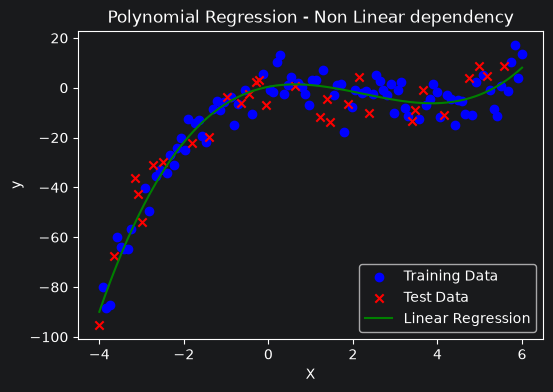

In [24]:
X_dense = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
y_dense_best = best_model.predict(X_dense)

plt.figure(figsize=(6, 4))
plt.scatter(X_train, y_train, color = 'blue', label = 'Training Data')
plt.scatter(X_test, y_test, color = 'red', label = 'Test Data', marker = 'x')
plt.plot(X_dense, y_dense_best, color = 'green', label = 'Linear Regression')
plt.title('Polynomial Regression - Non Linear dependency')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()

plt.show()

In [25]:
def fit_metrics_for_degree(d):
    pipe = Pipeline([
    ("poly", PolynomialFeatures(degree=d,include_bias=False)),
    ("lin", LinearRegression())
])
    pipe.fit(X_train, y_train)
    ytr = pipe.predict(X_train)
    yte = pipe.predict(X_test)
    return  pipe, {
        "degree": d,
        "train_R2": r2_score(y_train, ytr),
        "test_R2": r2_score(y_test, yte),
        "train_rmse": root_mean_squared_error(y_train, ytr),
        "test_rmse": root_mean_squared_error(y_test, yte),
    }

model_low, m_low = fit_metrics_for_degree(1)
model_best, m_best = best_model, {
    "degree": best_degree,
    "train_R2": r2_score(y_train, best_model.predict(X_train)),
        "test_R2": r2_score(y_test, best_model.predict(X_test)),
        "train_rmse": root_mean_squared_error(y_train, best_model.predict(X_train)),
        "test_rmse": root_mean_squared_error(y_test, best_model.predict(X_test)),
}

model_high, m_high = fit_metrics_for_degree(10)
pd.DataFrame([m_low, m_best, m_high])

,degree,train_R2,test_R2,train_rmse,test_rmse
0,1,0.473603,0.536308,15.914964,15.962790
1,3,0.934963,0.896711,5.594083,7.533914
2,10,0.888778,0.841149,7.315495,9.343056


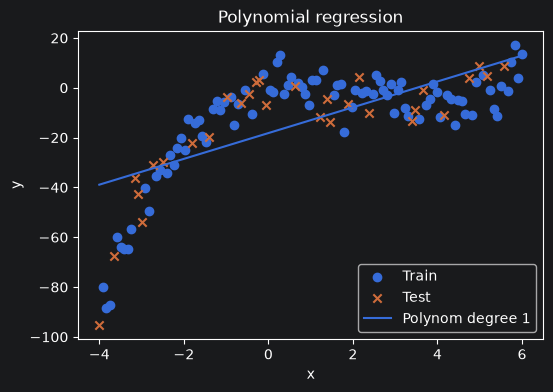

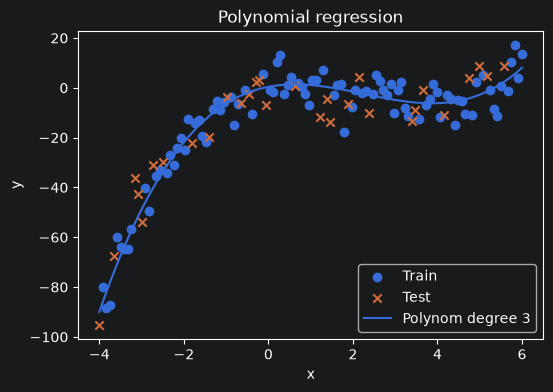

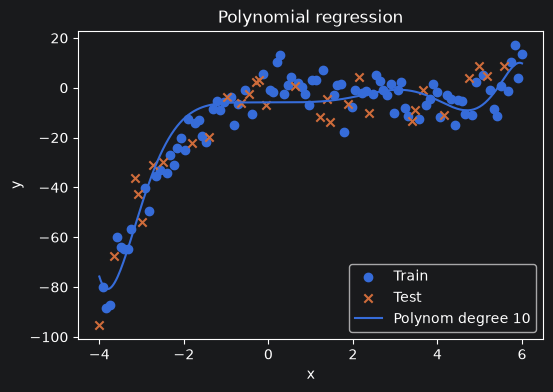

In [26]:
for d, model in [(1, model_low), (best_degree, model_best),(10, model_high)]:
    plt.figure(figsize=(6,4))
    y_curve = model.predict(X_dense)
    plt.scatter(X_train, y_train, label="Train")
    plt.scatter(X_test, y_test, label="Test", marker="x")
    plt.plot(X_dense, y_curve, label=f"Polynom degree {d}")
    plt.title("Polynomial regression")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.show()